In [8]:
import warnings
warnings.filterwarnings('ignore')

In [10]:
import numpy as np
import pandas as pd

In [12]:
import glob, os
glob.glob(os.path.expanduser('~/Downloads/*dvertis*'))

['/Users/riteshpardeshi/Downloads/advertising.csv']

In [16]:
advertising = pd.read_csv('/Users/riteshpardeshi/Downloads/advertising.csv')
advertising.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [18]:
advertising.shape

(200, 4)

In [20]:
advertising.isna().sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

In [22]:
advertising.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [28]:
advertising.dtypes

TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

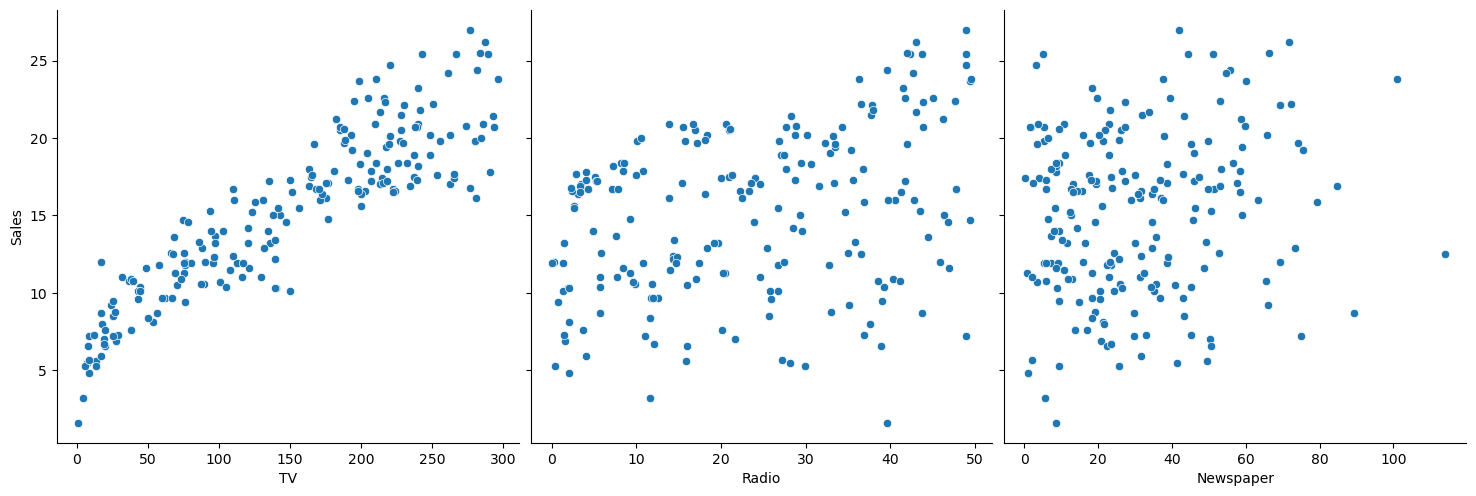

In [32]:
sns.pairplot(advertising,x_vars=['TV','Radio','Newspaper'],y_vars = ['Sales'],size=5)

In [34]:
advertising.corr()

,TV,Radio,Newspaper,Sales
TV,1.000000,0.054809,0.056648,0.901208
Radio,0.054809,1.000000,0.354104,0.349631
Newspaper,0.056648,0.354104,1.000000,0.157960
Sales,0.901208,0.349631,0.157960,1.000000


<Axes: >

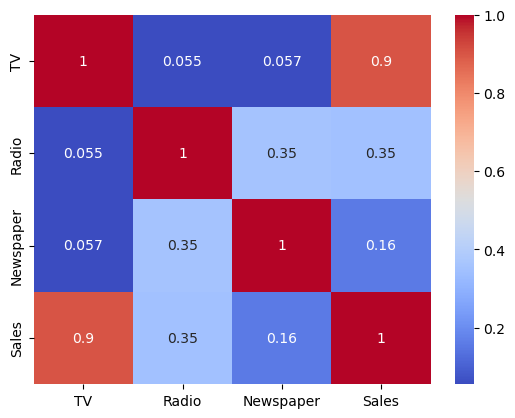

In [44]:
sns.heatmap(advertising.corr(),annot=True,cmap='coolwarm')

y= mx + c

sales = m * tv + c

the model is going to give us the value m and c

In [63]:
X = advertising['TV'] #independent variable

In [51]:
y = advertising['Sales'] # dependent variable

In [57]:
# this is a supervised ML model
# we do a train test split
# we train on the training dataset
# we apply on the test dataset

In [59]:
from sklearn.model_selection import train_test_split

In [65]:
X_train, X_test, y_train, y_test = train_test_split(X,y,train_size=0.7,test_size=0.3,random_state= 100)

In [67]:
# Building the model using statsmodel

import statsmodels.api as sm

In [69]:
X_train_sm = sm.add_constant(X_train)

In [73]:
X_train_sm.head()

,const,TV
74,1.0,213.4
3,1.0,151.5
185,1.0,205.0
26,1.0,142.9
90,1.0,134.3


In [ ]:
# Y = m * TV + Constant*c
# Y = m * TV + c

In [ ]:
# fit the line of best fit using OLS - Residual sum of squares

In [75]:
lr = sm.OLS(y_train,X_train_sm).fit()

In [77]:
lr.params

const    6.948683
TV       0.054546
dtype: float64

In [ ]:
c = 6.948683
m = 0.054546

# Sales = 0.05 * TV + 6.94

- With every one unit increase in TV Advertisements spend, the sales will go up by 0.05 units
- If 0 value is invested in TV adverstisement the sales will be 6.94 units

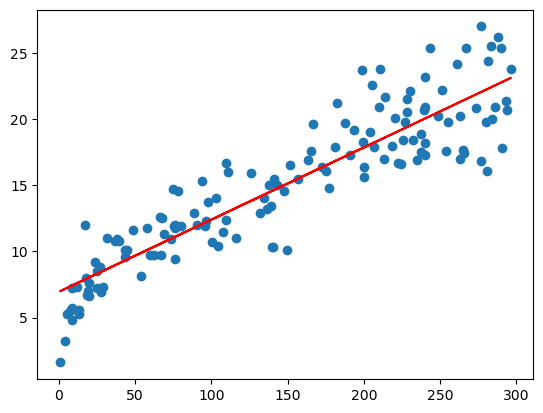

In [82]:
plt.scatter(X_train,y_train)
plt.plot(X_train,6.948683 + 0.054546 * X_train,'r')